In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# 16 - Long history and a synthetic-control counterfactual (1960-2024)
AMECO long series in national currency: compare countries through indices and ratios only. The synthetic Italy is a weighted mix of other countries that best reproduces Italy's real GDP per head before 1995; the gap afterwards is a *descriptive* measure of divergence from that peer mix, not a causal effect of any single policy (the donors are themselves exposed to the euro, the single market and global shocks).

Average annual growth of real GDP per head, % (decades):


,1960s,1970s,1980s,1990s,2000s,2010s,2020-24
iso3,,,,,,,
ITA,5.6,3.2,2.2,1.4,0.1,0.2,1.4
DEU,NaN,NaN,NaN,1.3,0.9,1.7,-0.3
FRA,4.4,3.4,1.8,1.6,0.9,0.9,0.5
ESP,6.3,2.7,2.2,2.2,1.2,0.9,0.6
median of other EU27,3.9,3.2,2.0,2.1,1.9,1.7,1.3


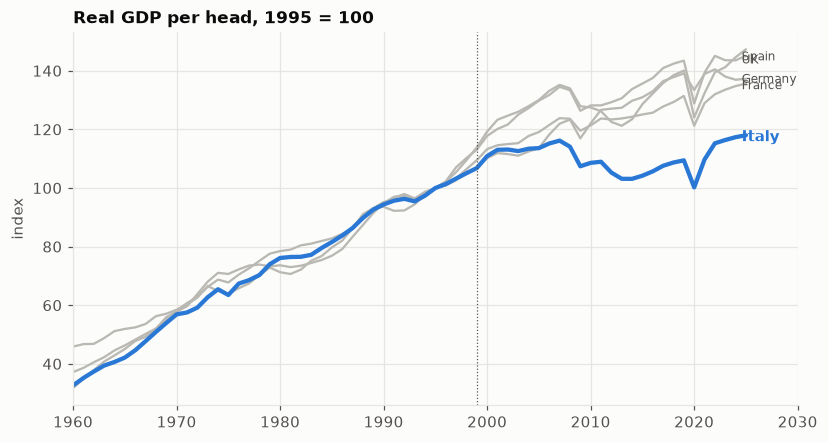

In [2]:
lh = load_long(); gdppc = long_wide(lh, "gdp_real_per_head_ncu")
idx = gdppc / gdppc.loc[1995] * 100
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for c, lab in [("DEU", "Germany"), ("FRA", "France"), ("ESP", "Spain"), ("GBR", "UK")]:
    ax.plot(idx.index, idx[c], color=PEER_C, lw=1.5); ax.annotate(lab, (2024, idx.loc[2024, c]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
ax.plot(idx.index, idx[ITALY], color=ITALY_C, lw=2.8); ax.annotate("Italy", (2024, idx.loc[2024, ITALY]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
ax.axvline(1999, color=INK2, lw=0.8, ls=":"); ax.annotate("euro", (1999.3, 20), fontsize=8, color=INK2); ax.set_title("Real GDP per head, 1995 = 100"); ax.set_ylabel("index"); ax.set_xlim(1960, 2030); save(fig, "16_gdp_per_head_long")
g = np.log(gdppc).diff() * 100; dec = pd.DataFrame({f"{d}s": g.loc[d:d + 9].mean() for d in range(1960, 2020, 10)}); dec["2020-24"] = g.loc[2020:2024].mean()
tab = dec.loc[[ITALY, "DEU", "FRA", "ESP"]]; tab.loc["median of other EU27"] = dec.loc[[c for c in EU27_ISO3 if c != ITALY and c in dec.index]].median()
print("Average annual growth of real GDP per head, % (decades):"); display(tab.round(1))

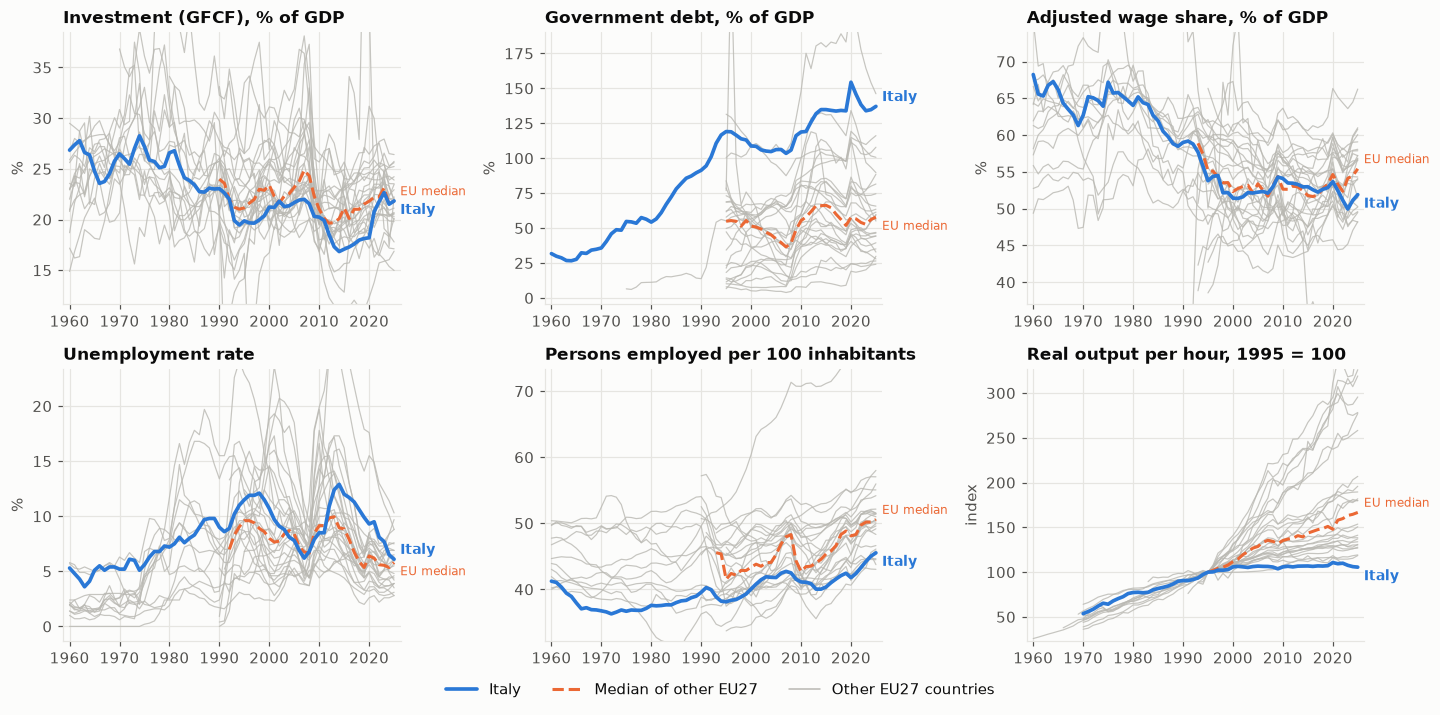

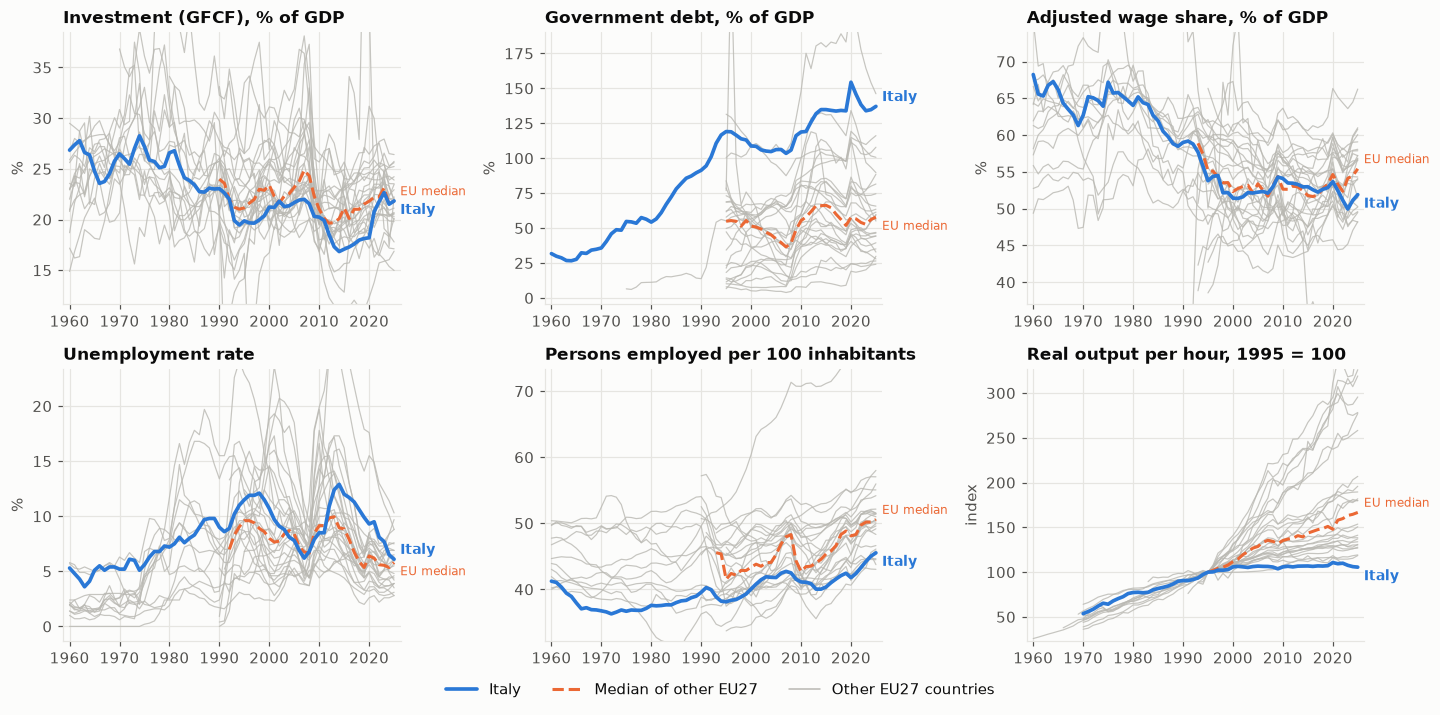

In [3]:
items = [(long_wide(lh, "gfcf_pct_gdp"), "Investment (GFCF), % of GDP", "%"), (long_wide(lh, "gov_debt_pct_gdp"), "Government debt, % of GDP", "%"),
         (long_wide(lh, "wage_share_adjusted_pct_gdp"), "Adjusted wage share, % of GDP", "%"), (long_wide(lh, "unemployment_rate"), "Unemployment rate", "%"),
         (long_wide(lh, "employment_per_head"), "Persons employed per 100 inhabitants", ""), (long_wide(lh, "gdp_real_per_hour_ncu") / long_wide(lh, "gdp_real_per_hour_ncu").loc[1995] * 100, "Real output per hour, 1995 = 100", "index")]
small_multiples_wide(items, ncols=3, name="16_long_overview")

Donor weights (> 1%): {'FRA': 0.42, 'AUT': 0.15, 'JPN': 0.13, 'FIN': 0.09, 'USA': 0.09, 'SWE': 0.07, 'IRL': 0.03, 'LUX': 0.02}
Pre-1995 fit RMSPE: 1.0 log points | gap (Italy minus synthetic) in 2005: -8.2, 2024: -19.1
Post/pre RMSPE ratio: Italy 16.4; rank 1 of 15; donors' median 3.1


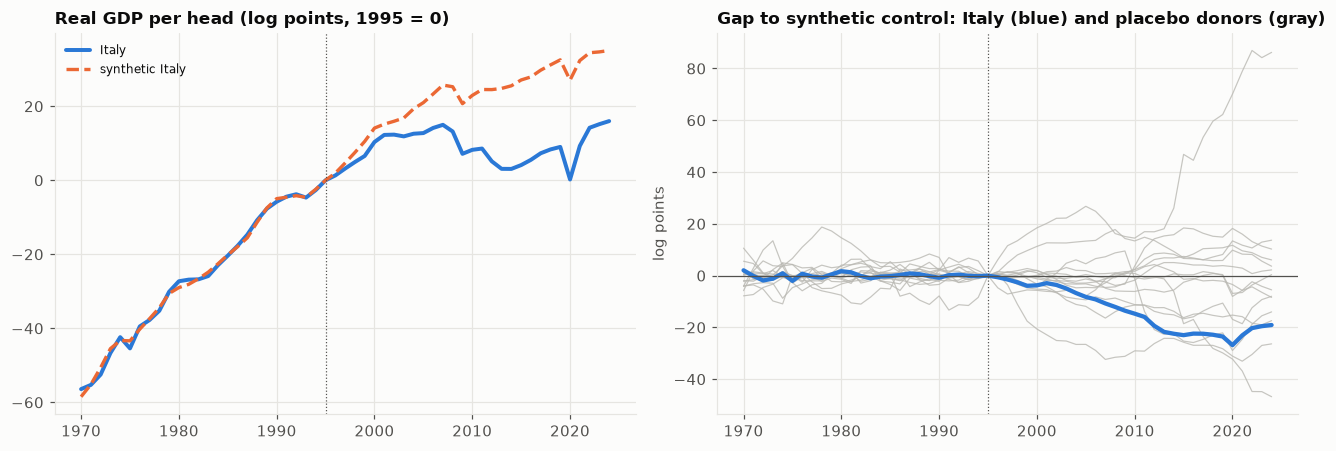

In [4]:
from cifresignificative.analysis.synth import synthetic_control, placebo_ratios, rmspe
y = np.log(gdppc); y = (y - y.loc[1995]) * 100  # log points relative to 1995
units = [c for c in ["AUT", "BEL", "DNK", "FIN", "FRA", "DEU", "GRC", "IRL", "LUX", "NLD", "PRT", "ESP", "SWE", "GBR", "USA", "JPN", ITALY] if y.loc[1970:2024, c].notna().all()]
donors = [c for c in units if c != ITALY]; pre = (1970, 1994)
w, synth = synthetic_control(y.loc[1970:2024], ITALY, pre, donors)
gap = y[ITALY] - synth
print("Donor weights (> 1%):", {k: round(v, 2) for k, v in w[w > 0.01].sort_values(ascending=False).items()})
print("Pre-1995 fit RMSPE: %.1f log points | gap (Italy minus synthetic) in 2005: %.1f, 2024: %.1f" % (rmspe(y[ITALY], synth, pre), gap.loc[2005], gap.loc[2024]))
ratios = placebo_ratios(y.loc[1970:2024, units], units, pre, (1995, 2024)); print("Post/pre RMSPE ratio: Italy %.1f; rank %d of %d; donors' median %.1f" % (ratios[ITALY], int(ratios.rank(ascending=False)[ITALY]), len(ratios), ratios.drop(ITALY).median()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(y.loc[1970:2024].index, y.loc[1970:2024, ITALY], color=ITALY_C, lw=2.6, label="Italy"); axes[0].plot(synth.index, synth, color=EU_C, lw=2.2, ls="--", label="synthetic Italy"); axes[0].axvline(1995, color=INK2, lw=0.8, ls=":")
axes[0].set_title("Real GDP per head (log points, 1995 = 0)"); axes[0].legend(fontsize=8)
for u in donors:
    _, s = synthetic_control(y.loc[1970:2024, units], u, pre, [c for c in units if c != u]); axes[1].plot(s.index, y.loc[1970:2024, u] - s, color=PEER_C, lw=0.8, alpha=0.8)
axes[1].plot(gap.index, gap, color=ITALY_C, lw=2.8); axes[1].axhline(0, color=INK2, lw=0.8); axes[1].axvline(1995, color=INK2, lw=0.8, ls=":"); axes[1].set_title("Gap to synthetic control: Italy (blue) and placebo donors (gray)"); axes[1].set_ylabel("log points")
fig.tight_layout(); save(fig, "16_synthetic_control")

## Takeaways (AMECO 1960-2024)
- **Growth faded in steps.** Real GDP per head grew 5.6% a year in the 1960s, 3.2% in the 1970s, 2.2% in the 1980s and 1.4% in the 1990s, then 0.1% in the 2000s and 0.2% in the 2010s (the median of other members: 3.9%, 3.2%, 2.0%, 2.1%, 1.9%, 1.7%). 2020-24 shows a rebound of 1.4% (median 1.3%). Italy was keeping pace until the 1980s and began to lag in the 1990s.
- **Counterfactual.** A synthetic Italy built from other countries (mostly France 42%, Austria 15%, Japan 13%, Finland 9%, USA 9%, Sweden 7%) tracks Italian GDP per head almost perfectly in 1970-1994 (error about 1 log point). From 1995 Italy falls behind: -8 log points by 2005 and -19 by 2024. Italy's post/pre error ratio is 16.4, the largest of the 15 units tested (donors' median 3.1), so the divergence is unusual relative to placebo comparisons.
- **Interpretation limits:** the donors are also exposed to the euro, the single market and global shocks, the pool is small (no donor can isolate one policy), and Germany is excluded because its series start in 1991. Read it as 'Italy's trajectory departs from its previous peer mix after 1995', not as the effect of one event.
- Other long series (investment, debt, unemployment, employment per head, output per hour) are in the figure for context; hours-based productivity has risen only 6% since 1995 vs 33% in Germany (notebook 17).